# 23CSE301 Machine Learning Capstone: Clustering Track

## UR3 Robot Telemetry Analysis (Review 1)

This notebook implements the data analysis and preprocessing pipeline for the UR3 Robot Telemetry dataset. The objective is to identify groups of similar robot operating states using sensor measurements such as current, temperature, and speed.

### Pipeline Structure
1. Dataset Loading
2. Dataset Audit
3. Exploratory Data Analysis (EDA)
4. Data Cleaning
5. Feature Selection and Engineering
6. Train / Test Split
7. Preprocessing and Feature Scaling
8. K-Means Clustering
9. Agglomerative Hierarchical Clustering
10. Clustering Evaluation and Visualization

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

## 1. Dataset Loading

We load the UR3 Robot Telemetry dataset from `data/ur3.xlsx`.

The dataset contains robot sensor measurements, including joint current, temperature, speed, and tool current. It also includes metadata such as timestamps and cycle information, along with event indicators for robot protective stops and grip loss.

The sensor measurements are used as features for clustering, while metadata and event indicators are excluded from the initial model inputs. Event indicators can be used later to help interpret the resulting clusters.

In [20]:
RANDOM_STATE = 42

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (10, 6)

df_raw = pd.read_excel("../data/clustering/ur3.xlsx")

# Standardize column names by removing surrounding whitespace
df = df_raw.copy()
df.columns = df.columns.str.strip()

print(f"Loaded dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

Loaded dataset shape: 7409 rows, 24 columns


,Num,Timestamp,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,...,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current,cycle,Robot_ProtectiveStop,grip_lost
0,1,2022-10-26T08:17:21.847Z,0.109628,27.875,-2.024669,29.3750,-1.531442,29.3750,-0.998570,32.1250,...,2.955651e-01,-0.000490,0.001310,-0.132836,-0.007479,-0.152962,0.082732,1,0.0,False
1,2,2022-10-26T08:17:22.852Z,0.595605,27.875,-2.278456,29.3125,-0.866556,29.4375,-0.206097,32.1875,...,-7.391485e-30,-0.000304,0.002185,0.001668,-0.000767,0.000417,0.505895,1,0.0,False
2,3,2022-10-26T08:17:23.857Z,-0.229474,27.875,-2.800408,29.3125,-2.304336,29.4375,-0.351499,32.1250,...,1.369386e-01,0.007795,-2.535874,0.379867,0.000455,-0.496856,0.079420,1,0.0,False
3,4,2022-10-26T08:17:24.863Z,0.065053,27.875,-3.687768,29.3125,-1.217652,29.4375,-1.209115,32.1250,...,-9.030032e-02,-0.004911,-0.009096,-0.384196,0.018411,0.425559,0.083325,1,0.0,False
4,5,2022-10-26T08:17:25.877Z,0.884140,27.875,-2.938830,29.3750,-1.794076,29.4375,-2.356471,32.1875,...,1.268088e-01,0.005567,0.001138,-0.353284,0.014994,0.180989,0.086379,1,0.0,False


## 2. Dataset Audit

We examine the dataset structure, data types, missing values, duplicate records, and descriptive statistics.

Since clustering does not use a target variable during training, the audit focuses on the quality and distribution of sensor measurements. Event indicators are examined separately for possible interpretation of the resulting clusters.

In [21]:
# 2.1 Dataset structure
print("Dataset shape:", df.shape)

print("\nColumn data types:")
display(df.dtypes.to_frame("Data Type"))

# 2.2 Missing-value audit
audit_df = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

print("\nDataset Audit Summary:")
display(audit_df)

# 2.3 Duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# 2.4 Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

# 2.5 Event indicator distributions
for col in ["Robot_ProtectiveStop", "grip_lost"]:
    if col in df.columns:
        print(f"\nDistribution of {col}:")
        display(df[col].value_counts(dropna=False).to_frame("Count"))

Dataset shape: (7409, 24)

Column data types:


,Data Type
Num,int64
Timestamp,str
Current_J0,float64
Temperature_T0,float64
Current_J1,float64
Temperature_J1,float64
Current_J2,float64
Temperature_J2,float64
Current_J3,float64
Temperature_J3,float64



Dataset Audit Summary:


,Data Type,Non-Null Count,Missing Count,Missing %
Num,int64,7409,0,0.00
Timestamp,str,7409,0,0.00
Current_J0,float64,7363,46,0.62
Temperature_T0,float64,7355,54,0.73
Current_J1,float64,7355,54,0.73
Temperature_J1,float64,7355,54,0.73
Current_J2,float64,7355,54,0.73
Temperature_J2,float64,7355,54,0.73
Current_J3,float64,7355,54,0.73
Temperature_J3,float64,7355,54,0.73



Exact duplicate rows: 0

Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Num,7409.0,NaN,NaN,NaN,3705.0,2138.938405,1.0,1853.0,3705.0,5557.0,7409.0
Timestamp,7409,7409,2022-10-26T08:17:21.847Z,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_J0,7363.0,NaN,NaN,NaN,-0.048934,0.829395,-6.247756,-0.195026,-0.08083,0.095959,6.806938
Temperature_T0,7355.0,NaN,NaN,NaN,34.906781,2.762057,27.8125,33.0,36.5,37.0625,37.25
Current_J1,7355.0,NaN,NaN,NaN,-2.297936,0.80045,-5.808734,-2.664919,-2.236342,-1.778334,1.083596
Temperature_J1,7355.0,NaN,NaN,NaN,37.659636,3.247315,29.3125,35.375,39.6875,40.125,40.5
Current_J2,7355.0,NaN,NaN,NaN,-1.199381,0.609984,-4.171966,-1.552803,-1.077137,-0.838721,2.46494
Temperature_J2,7355.0,NaN,NaN,NaN,38.064064,3.311948,29.375,35.75,40.1875,40.4375,40.9375
Current_J3,7355.0,NaN,NaN,NaN,-0.605312,0.514937,-3.333102,-0.830933,-0.57119,-0.388398,2.270268
Temperature_J3,7355.0,NaN,NaN,NaN,40.936999,3.182399,32.125,38.9375,43.0625,43.125,43.4375



Distribution of Robot_ProtectiveStop:


,Count
Robot_ProtectiveStop,
0.0,7077
1.0,278
NaN,54



Distribution of grip_lost:


,Count
grip_lost,
False,7166
True,243


### Dataset Audit Findings

The audit summarizes the number of observations, available features, missing values, duplicate records, and distributions of the event indicators.

The missing sensor values will be handled during preprocessing. Metadata and event indicators will be excluded from the clustering feature matrix to prevent them from directly influencing cluster formation.

## 3. Exploratory Data Analysis (EDA)

Exploratory data analysis is performed to understand the distribution and relationships of the robot sensor measurements.

We use histograms to examine individual sensor features, a correlation heatmap to investigate relationships between measurements, and plots of the event indicators to understand the available operational labels.

In [22]:
# Identify sensor measurement columns
sensor_cols = [
    col for col in df.columns
    if col.startswith(("Current_", "Temperature_", "Speed_"))
]

if "Tool_current" in df.columns:
    sensor_cols.append("Tool_current")

# Remove any accidental duplicate feature names
sensor_cols = list(dict.fromkeys(sensor_cols))

print("Number of sensor features:", len(sensor_cols))
print("Sensor features:", sensor_cols)

Number of sensor features: 19
Sensor features: ['Current_J0', 'Temperature_T0', 'Current_J1', 'Temperature_J1', 'Current_J2', 'Temperature_J2', 'Current_J3', 'Temperature_J3', 'Current_J4', 'Temperature_J4', 'Current_J5', 'Temperature_J5', 'Speed_J0', 'Speed_J1', 'Speed_J2', 'Speed_J3', 'Speed_J4', 'Speed_J5', 'Tool_current']


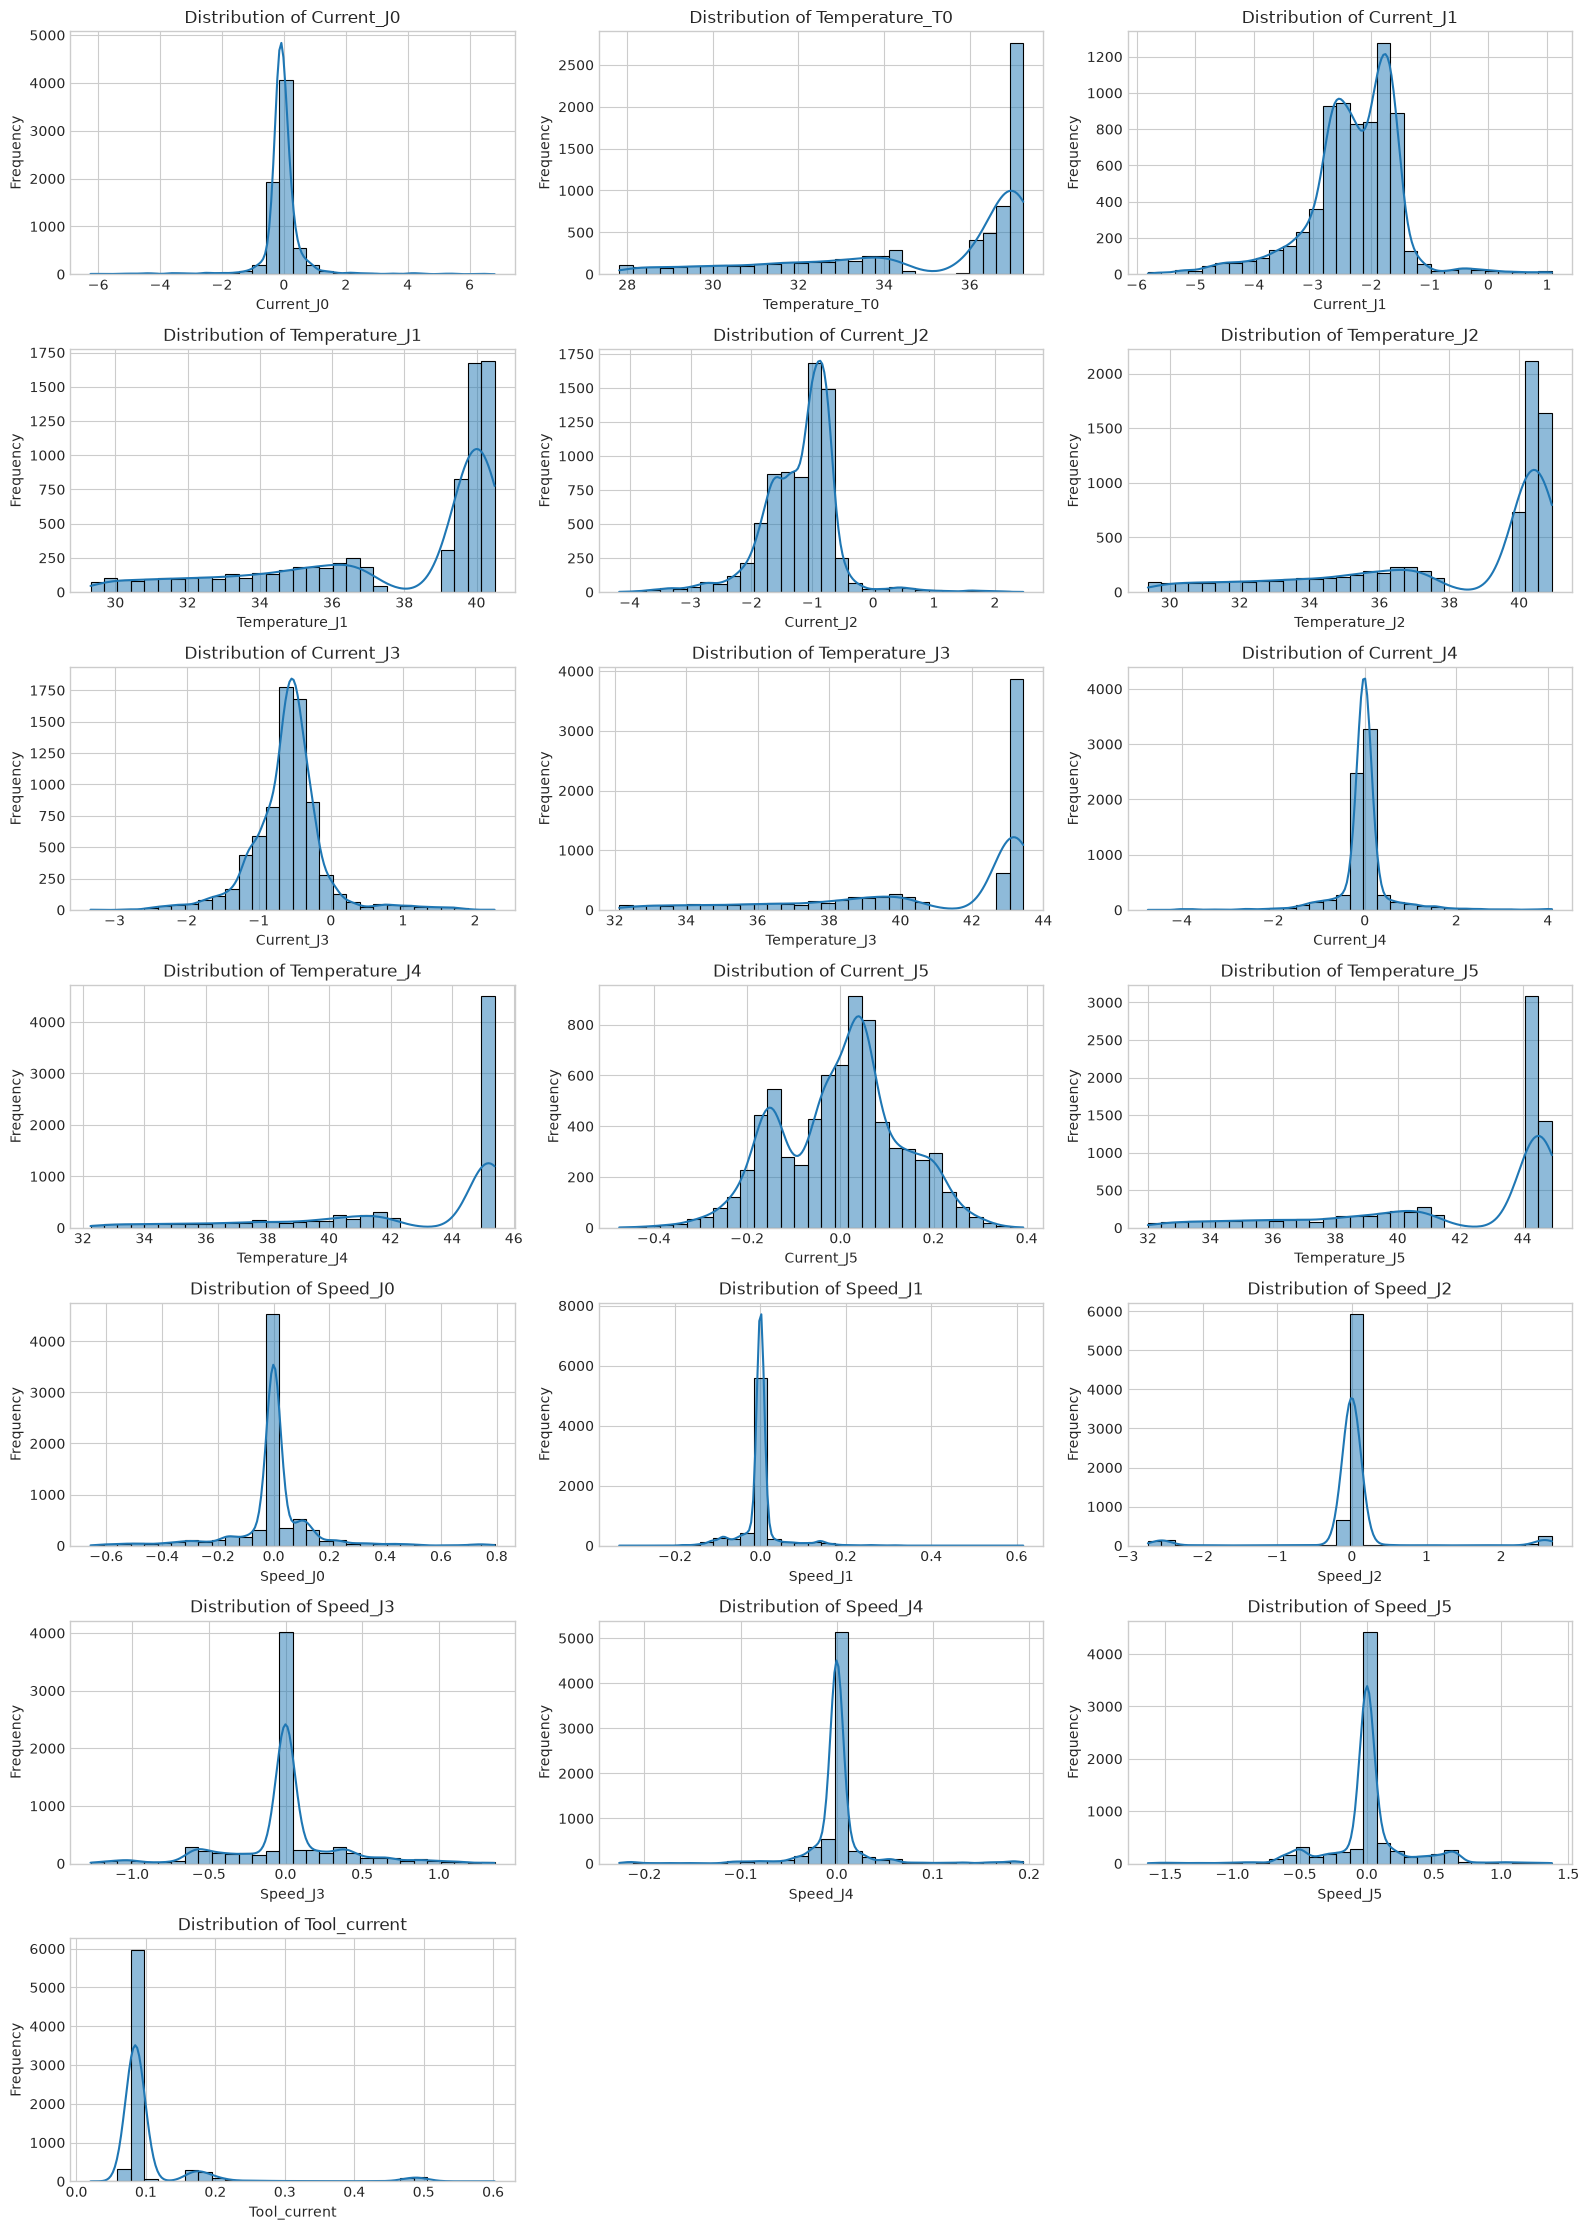

In [23]:
# 3.1 Distribution plots for sensor features

n_features = len(sensor_cols)
n_cols = 3
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, n_rows * 3.2)
)
axes = np.array(axes).flatten()

for i, col in enumerate(sensor_cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

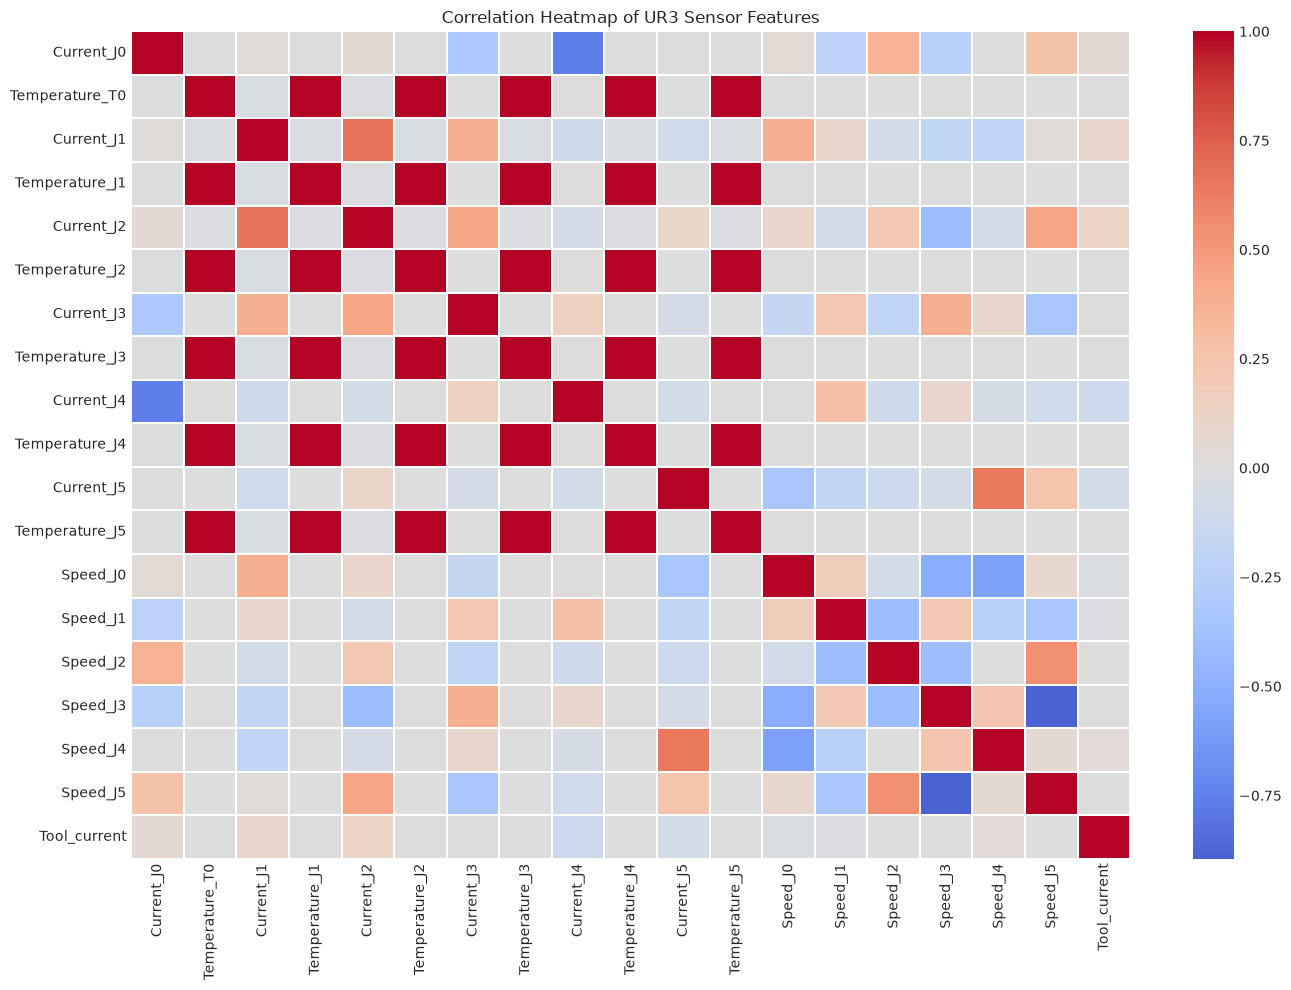

In [24]:
# 3.2 Correlation heatmap of sensor features

corr_matrix = df[sensor_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Heatmap of UR3 Sensor Features")
plt.tight_layout()
plt.show()

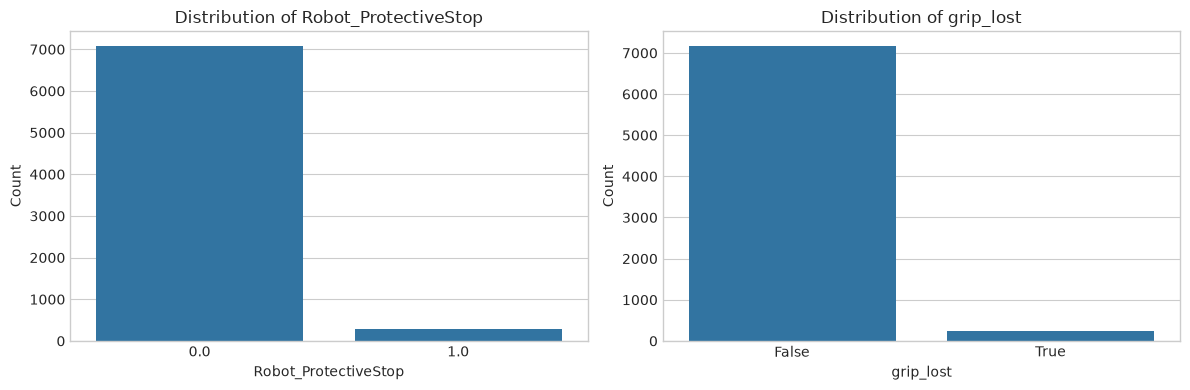

In [25]:
# 3.3 Event indicator distributions for later interpretation

event_cols = [
    col for col in ["Robot_ProtectiveStop", "grip_lost"]
    if col in df.columns
]

if event_cols:
    fig, axes = plt.subplots(
        1, len(event_cols),
        figsize=(6 * len(event_cols), 4)
    )

    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, event_cols):
        sns.countplot(data=df, x=col, ax=ax)
        ax.set_title(f"Distribution of {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Count")

    plt.tight_layout()
    plt.show()

### EDA Observations

- **Sensor distributions:** Examine the histograms for skewness, unusual values, and differences in the ranges of current, temperature, and speed measurements.
- **Correlation heatmap:** Identify sensor measurements that are strongly correlated and may provide similar information.
- **Event indicators:** Examine the frequency of protective stops and grip-loss events. These indicators are reserved for interpreting clusters after model fitting.

The observations should be finalized after examining the generated plots.

## 4. Data Cleaning

We check the dataset for duplicate records, missing sensor measurements, and potential outliers.

Duplicate records are removed if present. Missing sensor values are retained for median imputation during preprocessing. Potential outliers are identified and examined rather than automatically removed, since extreme sensor readings may represent meaningful robot operating states.

In [27]:
# 4.1 Check and remove exact duplicate records

duplicate_count = df.duplicated().sum()
print("Exact duplicate records detected:", duplicate_count)

df_cleaned = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df_cleaned.shape)

# 4.2 Missing-value summary for sensor features

missing_sensor = df_cleaned[sensor_cols].isna().sum()
missing_summary = pd.DataFrame({
    "Missing Count": missing_sensor,
    "Missing %": (
        missing_sensor / len(df_cleaned) * 100
    ).round(2)
})

print("\nMissing sensor values:")
display(missing_summary)

# 4.3 Outlier audit using the IQR rule

outlier_summary = []

for col in sensor_cols:
    values = df_cleaned[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count,
        "Outlier %": round(count / len(values) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\nPotential Outlier Summary:")
display(outlier_df.round(3))

Exact duplicate records detected: 0
Shape after duplicate removal: (7409, 24)

Missing sensor values:


,Missing Count,Missing %
Current_J0,46,0.62
Temperature_T0,54,0.73
Current_J1,54,0.73
Temperature_J1,54,0.73
Current_J2,54,0.73
Temperature_J2,54,0.73
Current_J3,54,0.73
Temperature_J3,54,0.73
Current_J4,54,0.73
Temperature_J4,54,0.73



Potential Outlier Summary:


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Current_J0,-0.632,0.532,967,13.13
1,Temperature_T0,26.906,43.156,0,0.00
2,Current_J1,-3.995,-0.448,412,5.60
3,Temperature_J1,28.250,47.250,0,0.00
4,Current_J2,-2.624,0.232,323,4.39
5,Temperature_J2,28.719,47.469,0,0.00
6,Current_J3,-1.495,0.275,579,7.87
7,Temperature_J3,32.656,49.406,104,1.41
8,Current_J4,-0.444,0.404,1313,17.85
9,Temperature_J4,33.156,52.406,139,1.89


### Data Cleaning Justification

- Duplicate records are removed to avoid giving repeated observations unnecessary influence during clustering.
- Missing sensor values are handled through median imputation in the preprocessing stage.
- Potential outliers are identified using the IQR rule but are not automatically removed or capped. Their significance should be assessed before deciding whether treatment is necessary.

## 5. Feature Selection and Engineering

The clustering feature matrix consists of 19 sensor measurements covering joint current, temperature, joint speed, and tool current.

Identifiers, timestamps, cycle information, and event indicators are excluded from the model inputs. This ensures that clusters are formed using sensor behaviour rather than record identity or pre-existing event labels.

The event indicators are retained separately for post-clustering interpretation.

In [28]:
# 5.1 Keep event indicators separately for later interpretation

event_cols = [
    col for col in ["Robot_ProtectiveStop", "grip_lost"]
    if col in df_cleaned.columns
]

event_labels = df_cleaned[event_cols].copy()

# 5.2 Select sensor features for clustering
X_raw = df_cleaned[sensor_cols].copy()

print("Clustering feature matrix shape:", X_raw.shape)
print("Number of selected features:", len(sensor_cols))

display(X_raw.head())

Clustering feature matrix shape: (7409, 19)
Number of selected features: 19


,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,Current_J4,Temperature_J4,Current_J5,Temperature_J5,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current
0,0.109628,27.875,-2.024669,29.3750,-1.531442,29.3750,-0.998570,32.1250,-0.062540,32.2500,-0.152622,32.0000,2.955651e-01,-0.000490,0.001310,-0.132836,-0.007479,-0.152962,0.082732
1,0.595605,27.875,-2.278456,29.3125,-0.866556,29.4375,-0.206097,32.1875,-1.062762,32.2500,-0.260764,32.0000,-7.391485e-30,-0.000304,0.002185,0.001668,-0.000767,0.000417,0.505895
2,-0.229474,27.875,-2.800408,29.3125,-2.304336,29.4375,-0.351499,32.1250,-0.668869,32.3125,0.039071,32.0625,1.369386e-01,0.007795,-2.535874,0.379867,0.000455,-0.496856,0.079420
3,0.065053,27.875,-3.687768,29.3125,-1.217652,29.4375,-1.209115,32.1250,-0.819755,32.2500,0.153903,32.0000,-9.030032e-02,-0.004911,-0.009096,-0.384196,0.018411,0.425559,0.083325
4,0.884140,27.875,-2.938830,29.3750,-1.794076,29.4375,-2.356471,32.1875,-0.966427,32.3125,0.178998,32.0000,1.268088e-01,0.005567,0.001138,-0.353284,0.014994,0.180989,0.086379


## 6. Train / Test Split

The sensor feature matrix is divided into training and testing sets using an 80:20 split, with `random_state=42` for reproducibility.

The split is performed before fitting the imputer and scaler to avoid data leakage. Since clustering is unsupervised, there is no target variable to split.

The training set will be used for the initial clustering experiments, while the testing set remains separate from preprocessing parameter estimation.

In [29]:
X_train_raw, X_test_raw = train_test_split(
    X_raw,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training set shape:", X_train_raw.shape)
print("Testing set shape:", X_test_raw.shape)

print(
    f"Training split: {len(X_train_raw) / len(X_raw):.1%}"
)
print(
    f"Testing split: {len(X_test_raw) / len(X_raw):.1%}"
)

Training set shape: (5927, 19)
Testing set shape: (1482, 19)
Training split: 80.0%
Testing split: 20.0%


## 7. Preprocessing and Feature Scaling

The sensor features are preprocessed using two steps:

1. **Median imputation:** Missing values are replaced using medians calculated from the training set.
2. **Standardization:** `StandardScaler` is fitted on the imputed training data so that features are placed on comparable scales.

Both preprocessing steps are fitted only on the training set and then applied to the test set. This avoids data leakage and prevents measurements with larger numerical ranges from dominating distance-based clustering.

In [30]:
# 7.1 Median imputation fitted only on training data

feature_names = X_train_raw.columns.tolist()

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=feature_names,
    index=X_train_raw.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=feature_names,
    index=X_test_raw.index
)

# 7.2 Standardization fitted only on training data

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imp),
    columns=feature_names,
    index=X_train_imp.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imp),
    columns=feature_names,
    index=X_test_imp.index
)

# 7.3 Validate preprocessing

assert X_train_scaled.isna().sum().sum() == 0
assert X_test_scaled.isna().sum().sum() == 0
assert X_train_scaled.shape[1] == X_test_scaled.shape[1]

print("Preprocessing validation passed.")
print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Features per sample:", X_train_scaled.shape[1])

display(X_train_scaled.head())

Preprocessing validation passed.
Training samples: 5927
Testing samples: 1482
Features per sample: 19


,Current_J0,Temperature_T0,Current_J1,Temperature_J1,Current_J2,Temperature_J2,Current_J3,Temperature_J3,Current_J4,Temperature_J4,Current_J5,Temperature_J5,Speed_J0,Speed_J1,Speed_J2,Speed_J3,Speed_J4,Speed_J5,Tool_current
5628,0.168985,0.774472,-1.008986,0.752479,-1.033121,0.728345,-0.863874,0.679682,0.012194,0.676909,0.228792,0.665955,0.001536,-0.004692,-0.009429,0.005942,0.013890,-0.008350,-0.274547
5246,0.412228,0.751666,-0.117083,0.713697,-0.259967,0.690319,-0.878041,0.659893,-0.660673,0.642666,-0.343318,0.665955,0.001536,-0.019089,-0.008991,0.004542,0.013890,-0.008350,4.751949
1049,-0.295525,-1.346506,0.670524,-1.361109,-1.991260,-1.344090,0.986696,-1.338860,0.322570,-1.326259,-1.541976,-1.368878,1.871622,0.232170,-0.075452,3.714345,-1.171360,-5.130562,-0.306074
626,-0.407384,-1.802630,-0.597878,-1.807095,0.770804,-1.819419,0.470097,-1.833601,0.262349,-1.822771,1.215297,-1.830563,-2.371620,0.029223,-0.024503,0.602941,0.339427,0.398530,-0.289758
2018,0.816920,-0.593900,-2.463814,-0.624262,-0.826773,-0.602576,-1.879792,-0.547275,-1.265441,-0.521568,1.137403,-0.565205,-0.395012,-2.236083,0.067017,-1.511489,0.643643,1.637828,-0.339811


## 8. Clustering Algorithms

Two unsupervised clustering algorithms are evaluated using the preprocessed sensor measurements.

- **K-Means Clustering:** The elbow method is used to examine inertia across different values of \(k\) and help select the number of clusters.
- **Agglomerative Hierarchical Clustering:** A dendrogram is used to examine hierarchical relationships between observations, and different linkage strategies are compared.

Both algorithms must be evaluated using the Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index. PCA-based visualizations will be used to display the resulting clusters, with a t-SNE visualization for at least one algorithm.